# ClusterBP v2: дополнительные анализы

1. Описание когорты и матрицы ошибок.
2. Клиническая полезность: калибровка, нагрузка тревогами, чувствительность для первых эпизодов, время упреждения, decision curve.
3. Абляции: XGB_full без фенотипа; покластерное слияние «только веса» и «только порог».
4. Выбор числа фенотипов k.
5. Другие табличные модели: Random Forest и HistGradientBoosting.

Используются окна, фолды, модели и предсказания из `clusterbp_v2.ipynb` и `clusterbp_v2_moe.ipynb`. Итоговая модель ClusterBP v2 — стекинг GRU и XGB_full (`Stack_global`).

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, brier_score_loss, silhouette_score

from clusterbp_lib import (RAW_DIR, DATA_DIR, CACHE_DIR, RESULTS_DIR, SEED, TARGETS, FEATURE_SETS, PHENO_COLS, N_FOLDS,
                           N_CLUST_PATIENTS, GDTW_WINDOW, GDTW_GAMMA, load_cached, fold_masks, add_phenotype_columns,
                           load_gru, load_xgb, gru_logits, sigmoid, logit, fit_xgb, best_threshold, tune_blend,
                           apply_blend, pairwise_gdtw, boot_eval, ci)

warnings.filterwarnings('ignore')
OUT = os.path.join(RESULTS_DIR, 'additional')
os.makedirs(OUT, exist_ok=True)
MAIN = ['A', 'B', 'OLD']
N_BOOT = 1000

win, X_seq, seq_len, pheno_win, oof = load_cached()
moe = pd.read_parquet(os.path.join(CACHE_DIR, 'oof_moe.parquet'))
for t in MAIN:
    oof[f'{t}__Stack_global__score'] = moe[f'{t}__Stack_global__score'].values
    oof[f'{t}__Stack_global__pred'] = moe[f'{t}__Stack_global__pred'].values
meas = pd.read_parquet(os.path.join(DATA_DIR, 'measurements.parquet'))
events = pd.read_parquet(os.path.join(DATA_DIR, 'events.parquet'))
pid = win['pid'].values
NAMES = {'Stack_global': 'ClusterBP v2 (стекинг GRU + XGB_full)', 'ClusterBP_full': 'ClusterBP v2, слияние по кластерам',
         'XGB_full': 'XGB_full', 'GRU': 'GRU', 'ClusterBP': 'ClusterBP v1', 'rule_maxSBP': 'правило: макс. САД'}


def paired(name, y, models, labels, ref):
    """Метрики и бутстреп-разности относительно модели ref."""
    B = boot_eval(y.astype(float), pid, models, n_boot=N_BOOT)
    rows = []
    for j, lab in enumerate(labels):
        s, p = models[j]
        d = B[:, j, 1] - B[:, labels.index(ref), 1]
        rows.append({'target': name, 'model': lab, 'AUROC': roc_auc_score(y, s), 'AUPRC': average_precision_score(y, s),
                     'AUPRC 95% ДИ': ci(B[:, j, 1]), 'macro_F1': f1_score(y, p, average='macro'),
                     f'ΔAUPRC к {ref}': average_precision_score(y, s) - average_precision_score(y, models[labels.index(ref)][0]),
                     'ΔAUPRC 95% ДИ': ci(d) if lab != ref else '',
                     'p': min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean())) if lab != ref else np.nan})
    return pd.DataFrame(rows)

## 1. Когорта и матрицы ошибок

In [2]:
grp = pd.read_csv(os.path.join(RAW_DIR, 'МО и Пациенты 10.04.2025.csv'), sep=';')
enrolled_programs = len(grp)
enrolled_patients = pd.to_numeric(grp['id пациента'].astype(str).str.replace(r'\s', '', regex=True), errors='coerce').nunique()
mp = meas.groupby('pid').agg(n=('td', 'size'), first=('td', 'min'), last=('td', 'max'))
mp['days'] = mp['last'] - mp['first']
coh = mp.loc[mp.index.isin(np.unique(pid))]
wpp = win.groupby('pid').size()
flow = pd.DataFrame({'значение': {
    'программ наблюдения в выгрузке': enrolled_programs,
    'уникальных пациентов в программах': enrolled_patients,
    'пациентов с измерениями после очистки': meas['pid'].nunique(),
    'пациентов хотя бы с одним окном (когорта моделирования)': len(coh),
    'окон': len(win),
    'измерений у пациентов когорты': int(coh['n'].sum()),
}})
desc = pd.DataFrame({
    'медиана': [coh['n'].median(), coh['days'].median(), wpp.median(), win['n_meas'].median()],
    'Q1': [coh['n'].quantile(.25), coh['days'].quantile(.25), wpp.quantile(.25), win['n_meas'].quantile(.25)],
    'Q3': [coh['n'].quantile(.75), coh['days'].quantile(.75), wpp.quantile(.75), win['n_meas'].quantile(.75)],
}, index=['измерений на пациента', 'длительность наблюдения, дней', 'окон на пациента', 'измерений в окне (14 дней)'])
flow.to_csv(os.path.join(OUT, 'cohort_flow.csv'))
desc.to_csv(os.path.join(OUT, 'cohort_description.csv'))
display(flow)
display(desc.round(1))

rows = []
for t in MAIN:
    y = win[f'y_{t}'].values
    for m in ['Stack_global', 'ClusterBP_full', 'XGB_full', 'ClusterBP', 'rule_maxSBP']:
        p = oof[f'{t}__{m}__pred'].values
        tp, fp = int(((p == 1) & (y == 1)).sum()), int(((p == 1) & (y == 0)).sum())
        fn, tn = int(((p == 0) & (y == 1)).sum()), int(((p == 0) & (y == 0)).sum())
        rows.append({'target': t, 'model': NAMES[m], 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
                     'доля событий': (tp + fn) / len(y), 'sensitivity': tp / (tp + fn), 'specificity': tn / (tn + fp),
                     'PPV': tp / max(tp + fp, 1), 'NPV': tn / max(tn + fn, 1)})
conf = pd.DataFrame(rows)
conf.to_csv(os.path.join(OUT, 'confusion_matrices.csv'), index=False)
display(conf.round(3))

,значение
программ наблюдения в выгрузке,13943
уникальных пациентов в программах,11739
пациентов с измерениями после очистки,10937
пациентов хотя бы с одним окном (когорта моделирования),9413
окон,420355
измерений у пациентов когорты,4758075


,медиана,Q1,Q3
измерений на пациента,360.0,153.0,715.0
"длительность наблюдения, дней",160.5,86.1,252.0
окон на пациента,39.0,16.0,67.0
измерений в окне (14 дней),39.0,21.0,69.0


,target,model,TP,FP,FN,TN,доля событий,sensitivity,specificity,PPV,NPV
0,A,ClusterBP v2 (стекинг GRU + XGB_full),8904,10449,10673,390329,0.047,0.455,0.974,0.460,0.973
1,A,"ClusterBP v2, слияние по кластерам",9207,11608,10370,389170,0.047,0.470,0.971,0.442,0.974
2,A,XGB_full,9030,11071,10547,389707,0.047,0.461,0.972,0.449,0.974
3,A,ClusterBP v1,8634,11537,10943,389241,0.047,0.441,0.971,0.428,0.973
4,A,правило: макс. САД,7927,16877,11650,383901,0.047,0.405,0.958,0.320,0.971
5,B,ClusterBP v2 (стекинг GRU + XGB_full),33997,19796,20933,345629,0.131,0.619,0.946,0.632,0.943
6,B,"ClusterBP v2, слияние по кластерам",34070,20191,20860,345234,0.131,0.620,0.945,0.628,0.943
7,B,XGB_full,34124,20398,20806,345027,0.131,0.621,0.944,0.626,0.943
8,B,ClusterBP v1,33381,20968,21549,344457,0.131,0.608,0.943,0.614,0.941
9,B,правило: макс. САД,23276,36993,31654,328432,0.131,0.424,0.899,0.386,0.912


## 2. Клиническая полезность

- **Калибровка:** наблюдаемая доля событий против предсказанной вероятности по децилям, ECE, наклон и сдвиг калибровки (логистическая регрессия исхода на logit вероятности; идеал — 1 и 0).
- **Нагрузка тревогами:** модель пересчитывается каждые 3 дня, поэтому число тревог на пациента в неделю = доля окон с тревогой × 7 / 3. Рабочие точки — порог из внутренней валидации (как в основной таблице) и пороги, дающие чувствительность 50%, 70% и 80% (выбираются по объединённым предсказаниям, описывают кривую, а не настройку).
- **Первые эпизоды:** чувствительность на окнах, где у пациента до отсечки не было ни одного события этого типа.
- **Уровень событий и время упреждения:** события одного типа у пациента за один день объединяются в эпизод. Эпизод считается замеченным, если хотя бы одно окно, чей горизонт его покрывает, дало тревогу; время упреждения — от самой ранней такой тревоги до эпизода.
- **Decision curve:** чистая польза (net benefit) в диапазоне пороговых вероятностей против стратегий «тревога всем» и «никому».

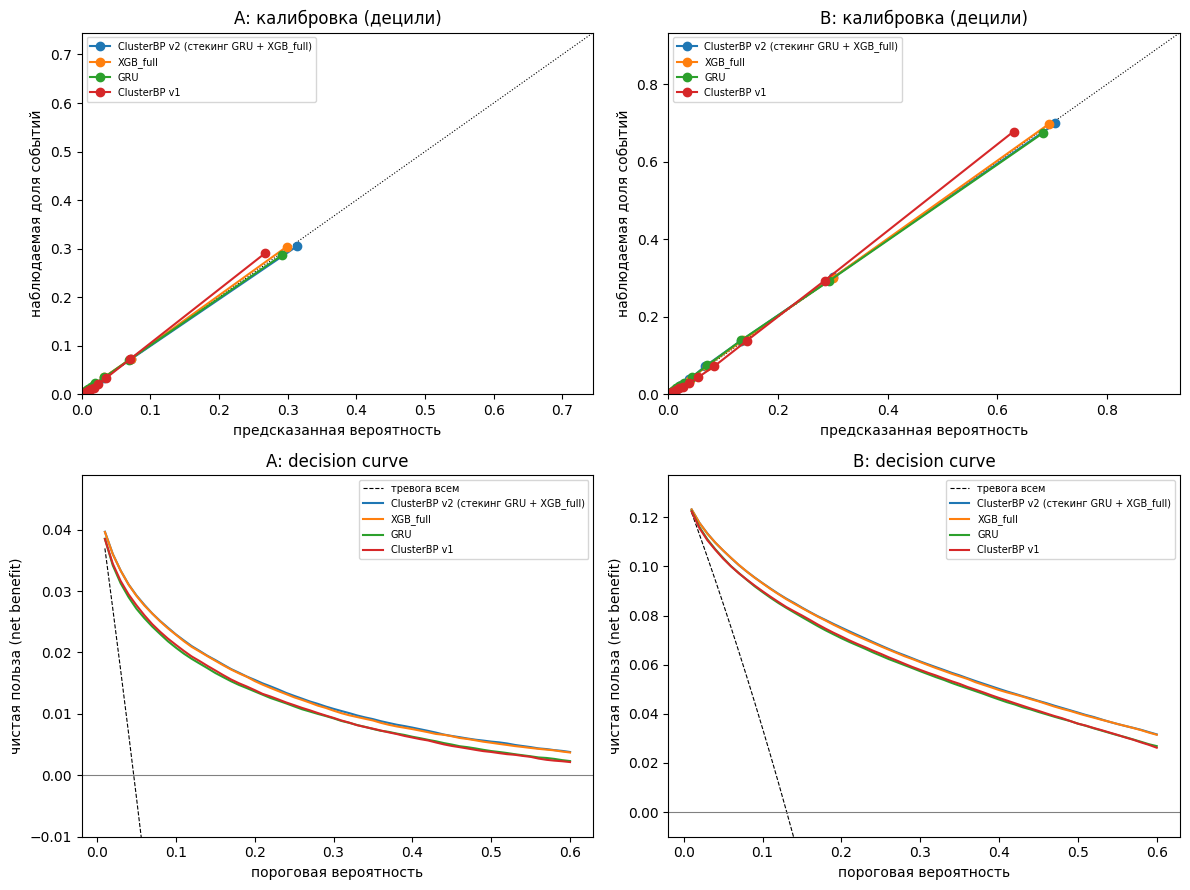


=== calibration ===


,target,model,Brier,ECE,наклон калибровки,сдвиг калибровки
0,A,ClusterBP v2 (стекинг GRU + XGB_full),0.033,0.001,0.995,-0.037
1,A,XGB_full,0.033,0.001,1.008,0.047
2,A,GRU,0.034,0.002,0.963,-0.055
3,A,ClusterBP v1,0.034,0.004,1.099,0.236
4,B,ClusterBP v2 (стекинг GRU + XGB_full),0.067,0.002,0.993,-0.006
5,B,XGB_full,0.067,0.002,1.014,0.023
6,B,GRU,0.071,0.003,0.979,-0.019
7,B,ClusterBP v1,0.071,0.011,1.129,0.170



=== alert_burden ===


,target,model,рабочая точка,sensitivity,PPV,тревог на пациента в неделю,тревог на одно событие (1/PPV)
0,A,ClusterBP v2 (стекинг GRU + XGB_full),порог валидации,0.455,0.460,0.107,2.174
1,A,ClusterBP v2 (стекинг GRU + XGB_full),чувствительность 50%,0.500,0.427,0.127,2.341
2,A,ClusterBP v2 (стекинг GRU + XGB_full),чувствительность 70%,0.700,0.272,0.279,3.673
3,A,ClusterBP v2 (стекинг GRU + XGB_full),чувствительность 80%,0.800,0.197,0.441,5.069
4,A,XGB_full,порог валидации,0.461,0.449,0.112,2.226
5,A,XGB_full,чувствительность 50%,0.500,0.420,0.129,2.381
6,A,XGB_full,чувствительность 70%,0.700,0.271,0.281,3.691
7,A,XGB_full,чувствительность 80%,0.800,0.196,0.443,5.091
8,A,GRU,порог валидации,0.439,0.423,0.113,2.366
9,A,GRU,чувствительность 50%,0.500,0.374,0.145,2.672



=== first_episodes ===


,target,model,положительных окон,из них первые эпизоды,чувствительность: все,чувствительность: первые эпизоды,чувствительность: повторные
0,A,ClusterBP v2 (стекинг GRU + XGB_full),19577,3691,0.455,0.024,0.555
1,A,XGB_full,19577,3691,0.461,0.015,0.565
2,A,GRU,19577,3691,0.439,0.083,0.521
3,A,ClusterBP v1,19577,3691,0.441,0.073,0.527
4,A,правило: макс. САД,19577,3691,0.405,0.056,0.486
5,B,ClusterBP v2 (стекинг GRU + XGB_full),54930,7481,0.619,0.037,0.711
6,B,XGB_full,54930,7481,0.621,0.030,0.714
7,B,GRU,54930,7481,0.592,0.116,0.667
8,B,ClusterBP v1,54930,7481,0.608,0.110,0.686
9,B,правило: макс. САД,54930,7481,0.424,0.165,0.465



=== episode_level ===


,target,model,эпизоды,n,доля замеченных,"упреждение, дней: медиана",Q1,Q3
0,A,ClusterBP v2 (стекинг GRU + XGB_full),все эпизоды,17553,0.618,6.137,5.186,7.067
1,A,ClusterBP v2 (стекинг GRU + XGB_full),первые эпизоды пациента,2880,0.097,3.573,1.814,5.424
2,A,XGB_full,все эпизоды,17553,0.623,6.141,5.191,7.069
3,A,XGB_full,первые эпизоды пациента,2880,0.086,3.140,1.809,4.718
4,A,GRU,все эпизоды,17553,0.618,6.093,5.132,7.012
5,A,GRU,первые эпизоды пациента,2880,0.178,4.605,2.295,6.255
6,A,ClusterBP v1,все эпизоды,17553,0.614,6.109,5.146,7.018
7,A,ClusterBP v1,первые эпизоды пациента,2880,0.165,4.367,2.394,6.096
8,A,правило: макс. САД,все эпизоды,17553,0.527,6.163,5.221,7.096
9,A,правило: макс. САД,первые эпизоды пациента,2880,0.117,4.332,2.454,6.397


In [3]:
PROB_MODELS = ['Stack_global', 'XGB_full', 'GRU', 'ClusterBP']


def calibration(y, p, bins=10):
    q = pd.qcut(pd.Series(p).rank(method='first'), bins, labels=False)
    obs = pd.Series(y).groupby(q.values).mean()
    pred = pd.Series(p).groupby(q.values).mean()
    ece = float((pd.Series(np.abs(obs - pred)) * pd.Series(q.values).value_counts(normalize=True).sort_index()).sum())
    lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
    return pred.values, obs.values, ece, lr.coef_[0][0], lr.intercept_[0]


def episode_level(t, score_pred):
    """Эпизоды (пациент, день) событий типа t: замечены ли и за сколько дней до эпизода была первая тревога."""
    cfg = TARGETS[t]
    ev = events[events.code.isin(cfg['codes'])].copy()
    ev['day'] = np.floor(ev['td'])
    ep = ev.groupby(['pid', 'day'])['td'].min().reset_index()
    order = np.lexsort((win['cut'].values, pid))
    w_pid, w_cut = pid[order], win['cut'].values[order]
    w_pred = score_pred[order]
    w_first = np.isnan(win[f'ev_{t}_days_since'].values[order])
    u, first_idx = np.unique(w_pid, return_index=True)
    starts = {p_: (a, b) for p_, a, b in zip(u, first_idx, np.r_[first_idx[1:], len(w_pid)])}
    res = []
    for p_, te in zip(ep['pid'].values, ep['td'].values):
        if p_ not in starts:
            continue
        a, b = starts[p_]
        cuts = w_cut[a:b]
        lo = np.searchsorted(cuts, te - cfg['gap'] - cfg['horizon'], side='right')
        hi = np.searchsorted(cuts, te - cfg['gap'], side='right')
        if hi <= lo:
            continue
        alerts = np.flatnonzero(w_pred[a:b][lo:hi] == 1)
        first_ep = bool(w_first[a:b][lo])
        res.append({'detected': len(alerts) > 0, 'lead': te - cuts[lo + alerts[0]] if len(alerts) else np.nan,
                    'first_episode': first_ep})
    return pd.DataFrame(res)


cal_rows, burden_rows, first_rows, ep_rows = [], [], [], []
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for col, t in enumerate(['A', 'B']):
    y = win[f'y_{t}'].values
    first = np.isnan(win[f'ev_{t}_days_since'].values)
    ax_cal, ax_dc = axes[0, col], axes[1, col]
    ax_cal.plot([0, 1], [0, 1], 'k:', lw=0.8)
    for m in PROB_MODELS:
        s = oof[f'{t}__{m}__score'].values
        pr, ob, ece, slope, inter = calibration(y, s)
        ax_cal.plot(pr, ob, 'o-', label=NAMES[m])
        cal_rows.append({'target': t, 'model': NAMES[m], 'Brier': brier_score_loss(y, s), 'ECE': ece,
                         'наклон калибровки': slope, 'сдвиг калибровки': inter})
    ax_cal.set_xlabel('предсказанная вероятность'); ax_cal.set_ylabel('наблюдаемая доля событий')
    ax_cal.set_title(f'{t}: калибровка (децили)'); ax_cal.legend(fontsize=7)
    lim = np.quantile(oof[f'{t}__Stack_global__score'], 0.995)
    ax_cal.set_xlim(0, lim); ax_cal.set_ylim(0, lim)

    for m in PROB_MODELS + ['rule_maxSBP']:
        s = oof[f'{t}__{m}__score'].values
        p = oof[f'{t}__{m}__pred'].values
        points = [('порог валидации', p)]
        pos_scores = np.sort(s[y == 1])
        for sens in [0.5, 0.7, 0.8]:
            thr = pos_scores[int((1 - sens) * len(pos_scores))]
            points.append((f'чувствительность {int(sens * 100)}%', (s >= thr).astype(int)))
        for label, pp in points:
            tp = ((pp == 1) & (y == 1)).sum(); fp = ((pp == 1) & (y == 0)).sum()
            burden_rows.append({'target': t, 'model': NAMES[m], 'рабочая точка': label,
                                'sensitivity': tp / y.sum(), 'PPV': tp / max(tp + fp, 1),
                                'тревог на пациента в неделю': pp.mean() * 7 / 3,
                                'тревог на одно событие (1/PPV)': (tp + fp) / max(tp, 1)})
        first_rows.append({'target': t, 'model': NAMES[m],
                           'положительных окон': int(y.sum()), 'из них первые эпизоды': int((y & first).sum()),
                           'чувствительность: все': p[y == 1].mean(),
                           'чувствительность: первые эпизоды': p[(y == 1) & first].mean(),
                           'чувствительность: повторные': p[(y == 1) & ~first].mean()})
        epi = episode_level(t, p)
        for subset, mask in [('все эпизоды', np.ones(len(epi), bool)), ('первые эпизоды пациента', epi['first_episode'].values)]:
            e = epi[mask]
            ep_rows.append({'target': t, 'model': NAMES[m], 'эпизоды': subset, 'n': len(e),
                            'доля замеченных': e['detected'].mean(),
                            'упреждение, дней: медиана': e['lead'].median(),
                            'Q1': e['lead'].quantile(.25), 'Q3': e['lead'].quantile(.75)})

    pts = np.linspace(0.01, 0.6, 60)
    prev = y.mean()
    ax_dc.plot(pts, prev - (1 - prev) * pts / (1 - pts), 'k--', lw=0.8, label='тревога всем')
    ax_dc.axhline(0, color='gray', lw=0.8)
    for m in PROB_MODELS:
        s = oof[f'{t}__{m}__score'].values
        nb = [((s >= q) & (y == 1)).mean() - ((s >= q) & (y == 0)).mean() * q / (1 - q) for q in pts]
        ax_dc.plot(pts, nb, label=NAMES[m])
    ax_dc.set_ylim(-0.01, prev * 1.05)
    ax_dc.set_xlabel('пороговая вероятность'); ax_dc.set_ylabel('чистая польза (net benefit)')
    ax_dc.set_title(f'{t}: decision curve'); ax_dc.legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'calibration_decision_curve.png'), dpi=200, bbox_inches='tight')
plt.show()

for name, rows in [('calibration', cal_rows), ('alert_burden', burden_rows), ('first_episodes', first_rows),
                   ('episode_level', ep_rows)]:
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(OUT, f'{name}.csv'), index=False)
    print(f'\n=== {name} ===')
    display(df.round(3))

## 3. Абляции

- **XGB_full без фенотипа:** та же модель без признаков `cluster` и расстояний до шаблонов — отвечает на вопрос, что даёт фенотип внутри модели.
- **Покластерное слияние по частям:** «только веса» (вес GRU по кластерам, порог общий) и «только порог» (вес общий, порог по кластерам) против глобального слияния и полного ClusterBP. Для ClusterBP v1 (GRU + XGB_paper6) и v2 (GRU + XGB_full).

Все параметры подбираются на внутренней валидации фолда.

In [4]:
NO_PHENO = [c for c in FEATURE_SETS['full'] if c not in PHENO_COLS]


def macro_f1_at(y, s, thr):
    p = s > thr
    tp = (p & (y == 1)).sum(); fp = (p & (y == 0)).sum(); fn = (~p & (y == 1)).sum(); tn = (~p & (y == 0)).sum()
    return (2 * tp / max(2 * tp + fp + fn, 1) + 2 * tn / max(2 * tn + fn + fp, 1)) / 2


def tune_partial(y, pg, px, cl, mode, weights=np.round(np.arange(0, 1.0001, 0.05), 2)):
    w_g, t_g = tune_blend(y, pg, px)['global']
    params = {}
    for c in np.unique(cl):
        m = cl == c
        if y[m].sum() < 30:
            params[int(c)] = (w_g, t_g)
        elif mode == 'weights':
            params[int(c)] = (max(weights, key=lambda w: macro_f1_at(y[m], w * pg[m] + (1 - w) * px[m], t_g)), t_g)
        else:
            params[int(c)] = (w_g, best_threshold(y[m], w_g * pg[m] + (1 - w_g) * px[m])[0])
    params['global'] = (w_g, t_g)
    return params


abl = {t: {} for t in MAIN}
t_all = time.time()
for k in range(N_FOLDS):
    tr, va, te = fold_masks(win, k)
    cl, _ = add_phenotype_columns(win, pheno_win, k)
    for t in MAIN:
        y = win[f'y_{t}'].values
        m = fit_xgb(win.loc[tr, NO_PHENO].values, y[tr], win.loc[va, NO_PHENO].values, y[va], SEED + k)
        s = m.predict_proba(win[NO_PHENO].values)[:, 1]
        thr, _ = best_threshold(y[va], s[va])
        abl[t].setdefault('XGB_full без фенотипа', [np.full(len(win), np.nan), np.zeros(len(win), np.int8)])
        abl[t]['XGB_full без фенотипа'][0][te] = s[te]
        abl[t]['XGB_full без фенотипа'][1][te] = (s[te] > thr)

        gm, mu, sd, corr = load_gru(t, k)
        pg = sigmoid(gru_logits(gm, X_seq, seq_len, mu, sd) + corr)
        for version, fs in [('v1', 'paper6'), ('v2', 'full')]:
            px = load_xgb(fs, t, k).predict_proba(win[FEATURE_SETS[fs]].values)[:, 1]
            variants = {
                f'{version}: глобальное слияние': (tune_blend(y[va], pg[va], px[va]), None),
                f'{version}: по кластерам только веса': (tune_partial(y[va], pg[va], px[va], cl[va], 'weights'), cl),
                f'{version}: по кластерам только порог': (tune_partial(y[va], pg[va], px[va], cl[va], 'threshold'), cl),
                f'{version}: по кластерам веса и порог (ClusterBP)': (tune_blend(y[va], pg[va], px[va], clusters=cl[va]), cl),
            }
            for name, (params, clusters) in variants.items():
                s, p = apply_blend(pg, px, params, clusters=clusters)
                st = abl[t].setdefault(name, [np.full(len(win), np.nan), np.zeros(len(win), np.int8)])
                st[0][te] = s[te]
                st[1][te] = p[te]
    print(f'Фолд {k}: {(time.time() - t_all) / 60:.1f} мин')

rows = []
for t in MAIN:
    y = win[f'y_{t}'].values
    labels = ['XGB_full'] + list(abl[t])
    models = [(oof[f'{t}__XGB_full__score'].values, oof[f'{t}__XGB_full__pred'].values.astype(float))]
    models += [(abl[t][n][0], abl[t][n][1].astype(float)) for n in abl[t]]
    B = boot_eval(y.astype(float), pid, models, n_boot=N_BOOT)
    ref = {'XGB_full без фенотипа': 'XGB_full'}
    for j, lab in enumerate(labels):
        r = ref.get(lab, f'{lab.split(":")[0]}: глобальное слияние' if ':' in lab else None)
        row = {'target': t, 'вариант': lab, 'AUPRC': average_precision_score(y, models[j][0]),
               'macro_F1': f1_score(y, models[j][1], average='macro'), 'macro_F1 95% ДИ': ci(B[:, j, 2])}
        if r and r != lab:
            jr = labels.index(r)
            for mi, metric in [(1, 'AUPRC'), (2, 'macro_F1')]:
                d = B[:, j, mi] - B[:, jr, mi]
                row[f'Δ{metric} к «{r}»'] = f'{np.mean(d):+.4f} {ci(d)}'
        rows.append(row)
ablation = pd.DataFrame(rows)
ablation.to_csv(os.path.join(OUT, 'ablations.csv'), index=False)
pd.set_option('display.max_colwidth', 80)
display(ablation.round(4))

Фолд 0: 0.6 мин


Фолд 1: 1.1 мин


Фолд 2: 1.7 мин


Фолд 3: 2.2 мин


Фолд 4: 2.7 мин


,target,вариант,AUPRC,macro_F1,macro_F1 95% ДИ,ΔAUPRC к «XGB_full»,Δmacro_F1 к «XGB_full»,ΔAUPRC к «v1: глобальное слияние»,Δmacro_F1 к «v1: глобальное слияние»,ΔAUPRC к «v2: глобальное слияние»,Δmacro_F1 к «v2: глобальное слияние»
0,A,XGB_full,0.4477,0.7141,[0.704; 0.723],NaN,NaN,NaN,NaN,NaN,NaN
1,A,XGB_full без фенотипа,0.4465,0.7136,[0.703; 0.723],-0.0012 [-0.003; 0.000],-0.0005 [-0.002; 0.001],NaN,NaN,NaN,NaN
2,A,v1: глобальное слияние,0.4049,0.7030,[0.692; 0.713],NaN,NaN,NaN,NaN,NaN,NaN
3,A,v1: по кластерам только веса,0.4038,0.7031,[0.692; 0.713],NaN,NaN,-0.0011 [-0.002; -0.000],+0.0000 [-0.001; 0.001],NaN,NaN
4,A,v1: по кластерам только порог,0.4049,0.7028,[0.692; 0.713],NaN,NaN,+0.0000 [0.000; 0.000],-0.0003 [-0.002; 0.001],NaN,NaN
5,A,v1: по кластерам веса и порог (ClusterBP),0.4059,0.7032,[0.692; 0.713],NaN,NaN,+0.0010 [-0.001; 0.003],+0.0002 [-0.002; 0.002],NaN,NaN
6,A,v2: глобальное слияние,0.4494,0.7150,[0.704; 0.725],NaN,NaN,NaN,NaN,NaN,NaN
7,A,v2: по кластерам только веса,0.4492,0.7149,[0.704; 0.725],NaN,NaN,NaN,NaN,-0.0002 [-0.001; 0.001],-0.0001 [-0.001; 0.001]
8,A,v2: по кластерам только порог,0.4494,0.7151,[0.705; 0.725],NaN,NaN,NaN,NaN,+0.0000 [0.000; 0.000],+0.0001 [-0.001; 0.001]
9,A,v2: по кластерам веса и порог (ClusterBP),0.4491,0.7142,[0.704; 0.724],NaN,NaN,NaN,NaN,-0.0002 [-0.001; 0.001],-0.0007 [-0.002; 0.000]


## 4. Выбор числа фенотипов k

Для каждого фолда — те же обучающие пациенты и та же процедура, что при построении шаблонов (GDTW + Ward), но k = 2…6.
Силуэт считается по матрице расстояний GDTW; «локоть» — по внутрикластерному разбросу W(k) = Σ по кластерам (сумма квадратов попарных расстояний / 2nₖ).

силуэт              W(k)          размер наименьшего кластера         
    mean    std       mean      std                        mean      std
k                                                                       
2  0.100  0.005  15630.709   90.498                       513.0   90.302
3  0.060  0.007  14899.895  154.123                       278.2  148.826
4  0.045  0.006  14382.175  119.683                       188.6   41.645
5  0.034  0.003  14013.170   51.820                       168.8   29.457
6  0.029  0.005  13740.119   42.380                       129.2   40.960

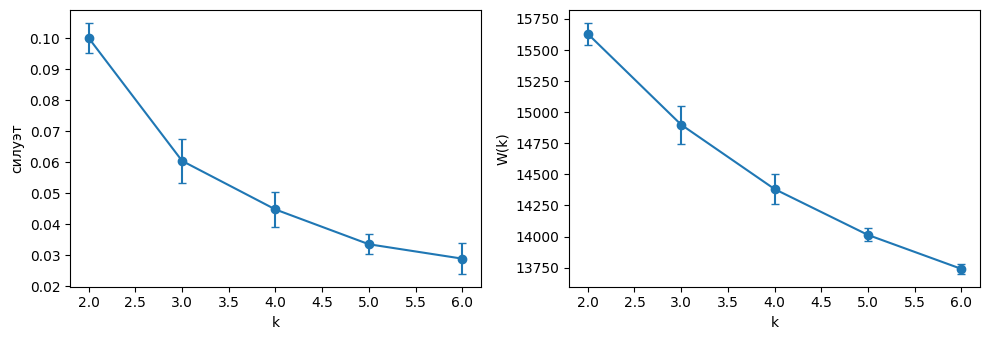

In [5]:
pheno_first = np.load(os.path.join(DATA_DIR, 'pheno_first.npy'))
pheno_first_pid = np.load(os.path.join(DATA_DIR, 'pheno_first_pid.npy'))
k_rows = []
for k in range(N_FOLDS):
    te = win['fold'].values == k
    train_pids = np.unique(pid[~te])
    P = pheno_first[np.isin(pheno_first_pid, train_pids)]
    valid = ~np.isnan(P)
    P = P[valid[:, 0] & valid[:, 25:].any(1) & (valid.sum(1) >= 15)]
    rng = np.random.default_rng(SEED + k)
    if len(P) > N_CLUST_PATIENTS:
        P = P[rng.choice(len(P), N_CLUST_PATIENTS, replace=False)]
    Dm = pairwise_gdtw(P, GDTW_WINDOW, GDTW_GAMMA)
    Dm = Dm + Dm.T
    Dm[~np.isfinite(Dm)] = np.nanmax(Dm[np.isfinite(Dm)])
    Z = linkage(squareform(Dm, checks=False), method='ward')
    for n_cl in range(2, 7):
        lab = fcluster(Z, n_cl, criterion='maxclust')
        W = sum((Dm[np.ix_(lab == c, lab == c)] ** 2).sum() / (2 * (lab == c).sum()) for c in np.unique(lab))
        k_rows.append({'fold': k, 'k': n_cl, 'силуэт': silhouette_score(Dm, lab, metric='precomputed'),
                       'W(k)': W, 'размер наименьшего кластера': np.bincount(lab)[1:].min()})
kdf = pd.DataFrame(k_rows)
kdf.to_csv(os.path.join(OUT, 'k_selection.csv'), index=False)
ks = kdf.groupby('k').agg(['mean', 'std']).drop(columns='fold')
display(ks.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].errorbar(ks.index, ks[('силуэт', 'mean')], yerr=ks[('силуэт', 'std')], fmt='o-', capsize=3)
axes[0].set_xlabel('k'); axes[0].set_ylabel('силуэт')
axes[1].errorbar(ks.index, ks[('W(k)', 'mean')], yerr=ks[('W(k)', 'std')], fmt='o-', capsize=3)
axes[1].set_xlabel('k'); axes[1].set_ylabel('W(k)')
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'k_selection.png'), dpi=200, bbox_inches='tight')
plt.show()

## 5. Другие табличные модели

Random Forest и HistGradientBoosting (градиентный бустинг на гистограммах, как LightGBM) на тех же 52 признаках, что XGB_full. Пороги — на внутренней валидации. Сравнение с XGB_full — бутстреп по пациентам.

In [6]:
tab = {t: {} for t in MAIN}
FULL = FEATURE_SETS['full']
t_all = time.time()
for k in range(N_FOLDS):
    tr, va, te = fold_masks(win, k)
    add_phenotype_columns(win, pheno_win, k)
    X = win[FULL].values.astype(float)
    for t in MAIN:
        y = win[f'y_{t}'].values
        models = {
            'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features='sqrt',
                                                    n_jobs=-1, random_state=SEED + k),
            'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=1000, learning_rate=0.05, max_leaf_nodes=31,
                                                                   early_stopping=True, validation_fraction=0.1,
                                                                   n_iter_no_change=50, random_state=SEED + k),
        }
        for name, model in models.items():
            model.fit(X[tr], y[tr])
            s = model.predict_proba(X)[:, 1]
            thr, _ = best_threshold(y[va], s[va])
            st = tab[t].setdefault(name, [np.full(len(win), np.nan), np.zeros(len(win), np.int8)])
            st[0][te] = s[te]
            st[1][te] = s[te] > thr
    print(f'Фолд {k}: {(time.time() - t_all) / 60:.1f} мин')

frames = []
for t in MAIN:
    y = win[f'y_{t}'].values
    labels = ['XGB_full', 'LR', 'Random Forest', 'HistGradientBoosting']
    models = [(oof[f'{t}__{m}__score'].values, oof[f'{t}__{m}__pred'].values.astype(float)) for m in ['XGB_full', 'LR']]
    models += [(tab[t][m][0], tab[t][m][1].astype(float)) for m in ['Random Forest', 'HistGradientBoosting']]
    frames.append(paired(t, y, models, labels, 'XGB_full'))
tabular = pd.concat(frames)
tabular.to_csv(os.path.join(OUT, 'tabular_models.csv'), index=False)
display(tabular.round(4))

Фолд 0: 3.2 мин


Фолд 1: 6.3 мин


Фолд 2: 9.4 мин


Фолд 3: 12.6 мин


Фолд 4: 15.8 мин


,target,model,AUROC,AUPRC,AUPRC 95% ДИ,macro_F1,ΔAUPRC к XGB_full,ΔAUPRC 95% ДИ,p
0,A,XGB_full,0.8964,0.4477,[0.419; 0.474],0.7141,0.0000,,NaN
1,A,LR,0.8742,0.4176,[0.388; 0.445],0.7060,-0.0301,[-0.036; -0.024],0.000
2,A,Random Forest,0.8934,0.4455,[0.417; 0.472],0.7139,-0.0022,[-0.005; 0.001],0.144
3,A,HistGradientBoosting,0.8900,0.4283,[0.399; 0.455],0.7074,-0.0194,[-0.023; -0.016],0.000
0,B,XGB_full,0.9102,0.6757,[0.658; 0.691],0.7836,0.0000,,NaN
1,B,LR,0.8947,0.6314,[0.614; 0.649],0.7736,-0.0442,[-0.049; -0.040],0.000
2,B,Random Forest,0.9087,0.6742,[0.657; 0.690],0.7831,-0.0015,[-0.003; -0.000],0.038
3,B,HistGradientBoosting,0.9083,0.6674,[0.650; 0.684],0.7808,-0.0083,[-0.010; -0.007],0.000
0,OLD,XGB_full,0.9279,0.5239,[0.497; 0.548],0.7419,0.0000,,NaN
1,OLD,LR,0.9146,0.4746,[0.446; 0.501],0.7287,-0.0493,[-0.055; -0.044],0.000
